<a href="https://colab.research.google.com/github/raneem-a1/IT326-Heart-Disease-project/blob/main/final_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT326 - Data Mining Project
# Final Report

---

## 1. Problem




##2. Data Mining Task


##3. Data

##4. Data Preprocessing

##5. Data Mining Technique
###**5.2 Clustering**

Clustering is an unsupervised data mining technique that groups similar data records based on their features without relying on predefined class labels. In this project, the K-Means algorithm is used to explore similarities and identify potential groups within the Heart Disease dataset.

**-Why K-Means was selected**

K-Means was selected because it is a commonly used clustering algorithm that assigns records to clusters based on their distances from cluster centroids. It also allows the results to be compared by changing the number of clusters, making it suitable for investigating different groupings in the dataset.

**-Python Packages and Methods**

The following Python packages and methods are used:

Pandas (pandas): Used to organize the dataset and select the features for clustering.

Scikit-learn (sklearn.cluster.KMeans): Used to create and fit the K-Means clustering models.

Scikit-learn (sklearn.metrics.silhouette_score): Used to calculate the average Silhouette Coefficient for each clustering solution.

Scikit-learn (sklearn.metrics.calinski_harabasz_score): Used as an additional metric to assess the separation between clusters relative to their internal dispersion.

Matplotlib (matplotlib.pyplot): Used to plot the Elbow curve and visualize the clusters.

**-How Clustering is Applied**

The selected input features are used to fit K-Means models with three different values of K: K = 2, K = 3, and K = 4. The target attribute is excluded from the clustering inputs because the purpose is to discover groups based on the data features rather than use the known class labels to form the clusters.

**-The three K values are compared using the following evaluation methods:**

1. Silhouette Coefficient: Measures how well each record fits within its assigned cluster compared with other clusters. Higher values generally indicate better-defined clusters.

2. Elbow Method: Uses the Total Within-Cluster Sum of Squares (WCSS), available through the K-Means model's inertia_ attribute, to examine how within-cluster variation changes as K increases. The Elbow curve is inspected to identify a suitable number of clusters.

3. Calinski-Harabasz Index: Included as an additional evaluation metric. A higher score generally indicates better-defined clusters according to the relationship between between-cluster dispersion and within-cluster dispersion.

**The clustering results** are visualized using scatter plots, with Age (age) on the x-axis and Maximum Heart Rate (thalach) on the y-axis, and cluster assignments represented by different colors. These plots help illustrate the distribution and overlap of the identified groups.

Finally, the evaluation results from the three K values are compared. The majority rule is used to identify the preferred K based on the evaluation methods, while the cluster visualizations are examined to help interpret the resulting groups.

##6. Evalution and Comparison
### **6.2.1 Summary Table of Results**

The K-Means clustering algorithm was evaluated using three different values of K: 2, 3, and 4. The Average Silhouette Width and Total Within-Cluster Sum of Squares (WCSS) were used as the main evaluation measures, as required by the project guidelines. The Calinski-Harabasz Index was also included as an additional metric to support the selection of the optimal number of clusters.

The results are summarized in the following table:

| Evaluation Metric | K = 2 | K = 3 | K = 4 |
|---|---:|---:|---:|
| Average Silhouette Width | 0.2455 | 0.2441 | 0.1934 |
| Total WCSS | 2969.31 | 2355.74 | 2124.55 |
| Calinski-Harabasz Index | 356.43 | 357.51 | 301.05 |

The results show that K = 2 achieved the highest Silhouette score, indicating relatively better-defined clusters according to this metric. K = 3 achieved the highest Calinski-Harabasz score. The WCSS decreased as the number of clusters increased, so the Elbow Method was used to examine the rate of decrease and identify a suitable number of clusters.



### **6.2.2 Interpretation of Results for Each K**

**K = 2**

When K = 2, the Silhouette score was **0.2455**, the highest among the three tested values. This indicates that K = 2 achieved the best clustering quality according to the Silhouette metric. However, its WCSS was **2969.31**, which was higher than the WCSS values obtained with K = 3 and K = 4. The Calinski-Harabasz Index was **356.43**, slightly lower than the score for K = 3.

**K = 3**

When K = 3, the Silhouette score was **0.2441**, which was very close to the score for K = 2. The WCSS decreased to **2355.74**, representing a substantial reduction compared with K = 2. In addition, K = 3 achieved the highest Calinski-Harabasz Index of **357.51**. The Elbow Method also favored K = 3 because the reduction in WCSS became smaller when increasing K from 3 to 4. These results suggest that K = 3 provides a reasonable balance between reducing within-cluster variation and avoiding unnecessary additional clusters.

**K = 4**

When K = 4, the WCSS reached its lowest value of **2124.55**. However, the Silhouette score decreased to **0.1934**, and the Calinski-Harabasz Index decreased to **301.05**. Although adding a fourth cluster reduced WCSS further, the improvement was smaller than the reduction observed when moving from K = 2 to K = 3. Therefore, K = 4 did not provide an overall improvement across the evaluation metrics.



### **6.2.3 Identifying the Best K Using Majority Rule**

To determine the most suitable number of clusters, the results of the three evaluation methods were compared using the majority rule.

| Evaluation Method | Preferred K | Reason |
|---|---:|---|
| Silhouette Coefficient | K = 2 | Achieved the highest Silhouette score of 0.2455. |
| Elbow Method (WCSS) | K = 3 | The decrease in WCSS became smaller after K = 3. |
| Calinski-Harabasz Index | K = 3 | Achieved the highest score of 357.51. |

Based on the majority rule, **K = 3 was selected as the preferred number of clusters**, since two out of the three evaluation methods favored this value. Although K = 2 achieved a slightly higher Silhouette score, K = 3 provided a reasonable balance between clustering quality and within-cluster variation.

However, the Silhouette scores were relatively low for all tested values, indicating that the clusters were not strongly separated. Therefore, the clustering results should be interpreted with caution.


### **6.2.4 Visualization of Clusters**

The clustering results were visualized using scatter plots to examine the distribution of records for K = 2, K = 3, and K = 4. Age (`age`) is represented on the x-axis, while Maximum Heart Rate (`thalach`) is represented on the y-axis. Different colors represent the clusters identified by the K-Means algorithm.

These visualizations help illustrate how the records are grouped for each value of K and allow us to compare the distribution and overlap of the identified clusters.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv('Preprocessed_dataset.csv')
print(df.shape)


from sklearn.cluster import KMeans

X_cluster = df.drop(columns=['target', 'age_group'])

print("Clustering data shape:", X_cluster.shape)
X_cluster.head()

(1025, 15)
Clustering data shape: (1025, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.479167,1,0,0.292453,0.196347,0,1,0.740458,0,0.351124,2,2,3
1,0.500000,1,0,0.433962,0.175799,1,0,0.641221,1,0.714756,0,0,3
2,0.854167,1,0,0.481132,0.109589,0,1,0.412214,1,0.648876,0,0,3
3,0.666667,1,0,0.509434,0.175799,0,1,0.687023,0,0.000000,2,1,3
4,0.687500,0,0,0.415094,0.383562,1,1,0.267176,0,0.539345,1,3,2


In [3]:
k_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_cluster)

    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    print(f"K = {k}")
    print("Cluster counts:")
    print(pd.Series(labels).value_counts().sort_index())
    print()

K = 2
Cluster counts:
0    524
1    501
Name: count, dtype: int64

K = 3
Cluster counts:
0    353
1    468
2    204
Name: count, dtype: int64

K = 4
Cluster counts:
0    204
1    271
2    329
3    221
Name: count, dtype: int64



In [4]:
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in k_values:
    score = silhouette_score(X_cluster, cluster_labels[k])
    silhouette_scores[k] = score

    print(f"K = {k}, Average Silhouette Width = {score:.4f}")

K = 2, Average Silhouette Width = 0.2455
K = 3, Average Silhouette Width = 0.2441
K = 4, Average Silhouette Width = 0.1934


In [5]:
wcss = {}

for k in k_values:
    wcss[k] = kmeans_models[k].inertia_

    print(f"K = {k}, Total WCSS = {wcss[k]:.2f}")

K = 2, Total WCSS = 2969.31
K = 3, Total WCSS = 2355.74
K = 4, Total WCSS = 2124.55


In [6]:
from sklearn.metrics import calinski_harabasz_score

calinski_scores = {}

for k in k_values:
    score = calinski_harabasz_score(
        X_cluster,
        cluster_labels[k]
    )

    calinski_scores[k] = score

    print(f"K = {k}, Calinski-Harabasz Score = {score:.2f}")

K = 2, Calinski-Harabasz Score = 356.43
K = 3, Calinski-Harabasz Score = 357.51
K = 4, Calinski-Harabasz Score = 301.05


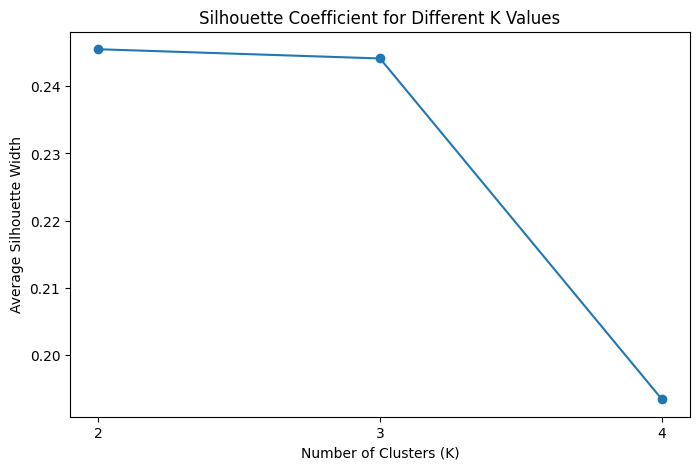

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    [silhouette_scores[k] for k in k_values],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Width')
plt.title('Silhouette Coefficient for Different K Values')
plt.xticks(k_values)

plt.show()

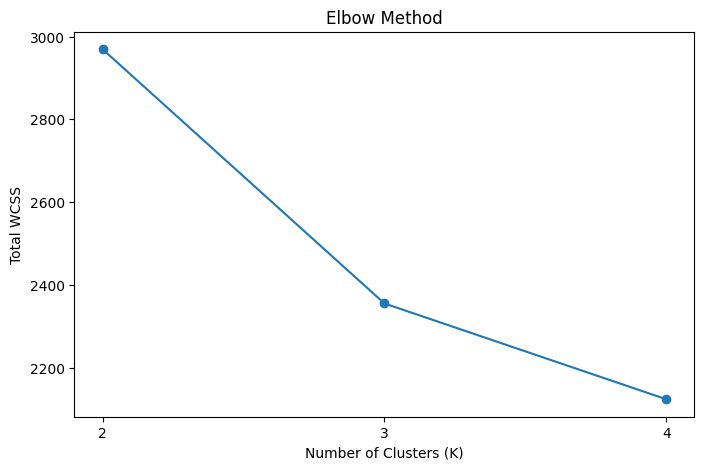

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    [wcss[k] for k in k_values],
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Total WCSS')
plt.title('Elbow Method')
plt.xticks(k_values)

plt.show()

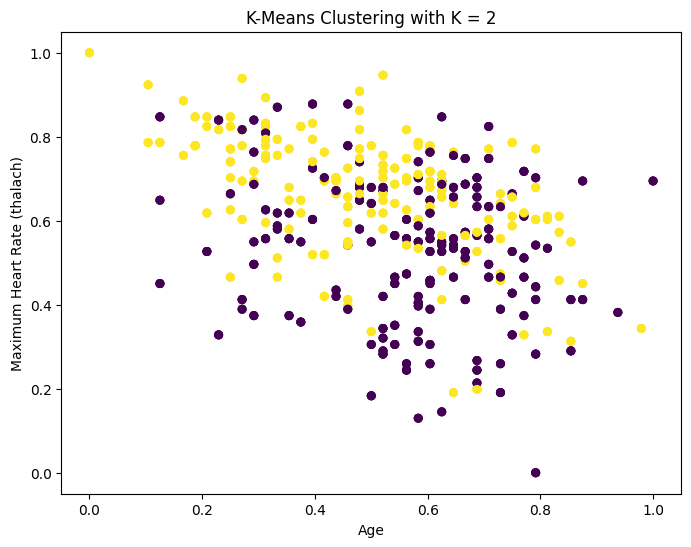

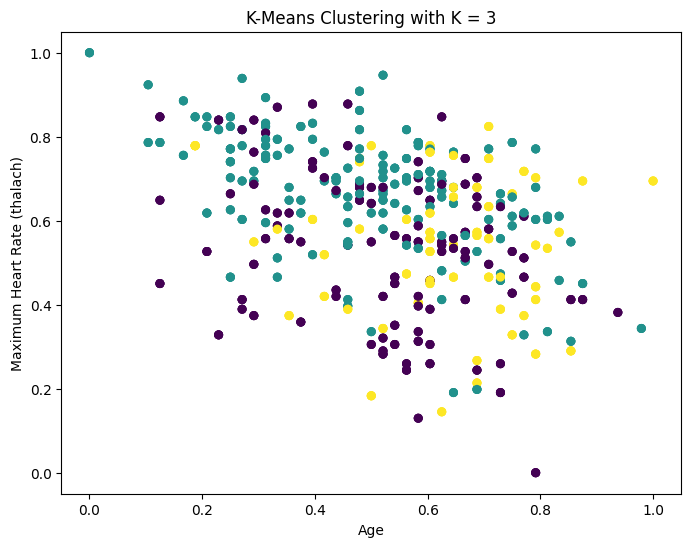

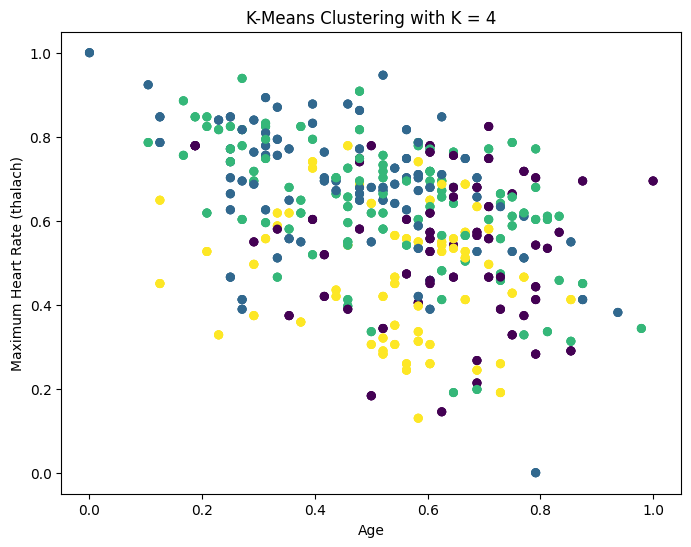

In [9]:
# K-Means Clustering with K = 2
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[2],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 2')
plt.show()


# K-Means Clustering with K = 3
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[3],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 3')
plt.show()


# K-Means Clustering with K = 4
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['age'],
    X_cluster['thalach'],
    c=cluster_labels[4],
    cmap='viridis',
    s=30
)

plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate (thalach)')
plt.title('K-Means Clustering with K = 4')
plt.show()

##7. Findings and Discussion

##8. References